## Оценка зависимости зарплаты от опыта работы (линейная регрессия)

Импорт библиотек и загрузка датасета:

In [56]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import sklearn.metrics as sklmetr
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [2]:
salary_data = pd.read_csv("Salary Data.csv")
salary_data.head()

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


In [3]:
salary_data.shape

(30, 2)

In [4]:
salary_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     float64
dtypes: float64(2)
memory usage: 612.0 bytes


In [5]:
salary_data.describe()

,YearsExperience,Salary
count,30.000000,30.000000
mean,5.313333,76003.000000
std,2.837888,27414.429785
min,1.100000,37731.000000
25%,3.200000,56720.750000
50%,4.700000,65237.000000
75%,7.700000,100544.750000
max,10.500000,122391.000000


In [6]:
salary_data.isna().sum()

,0
YearsExperience,0
Salary,0


### Корреляция:

<Axes: >

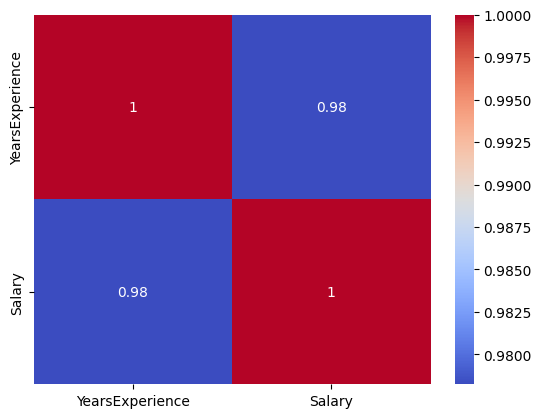

In [51]:
sns.heatmap(salary_data.corr(), annot=True, cmap='coolwarm')

### Диаграмма рассеивания:

<Axes: xlabel='YearsExperience', ylabel='Salary'>

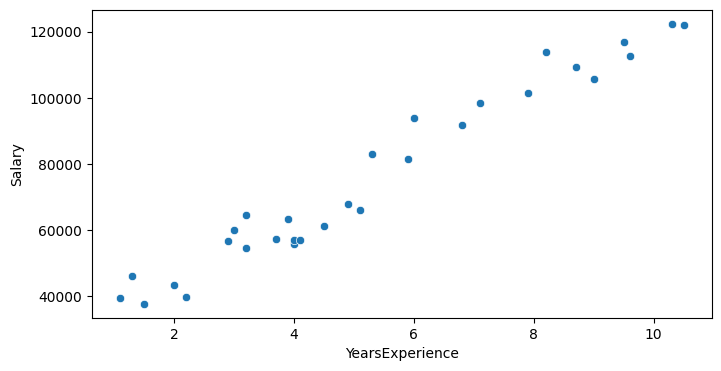

In [46]:
plt.figure(figsize=(8, 4))
sns.scatterplot(x='YearsExperience', y='Salary', data=salary_data)


### Линейная регрессия

In [32]:
x = salary_data.iloc[:,:-1].values
y = salary_data.iloc[:, 1].values
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.20, random_state=1)
print(f"x_train: {x_train.shape}")
print(f"x_test: {x_test.shape}")
print(f"y_train: {y_train.shape}")
print(f"y_test: {y_test.shape}")

x_train: (24, 1)
x_test: (6, 1)
y_train: (24,)
y_test: (6,)


In [37]:
regressor = LinearRegression()
regressor.fit(x_train, y_train)
print(f"Коэффициент наклона: {regressor.coef_};\nСвободный член: {regressor.intercept_}")

Коэффициент наклона: [9332.94473799];
Свободный член: 25609.89799835482


<Axes: xlabel='YearsExperience', ylabel='Salary'>

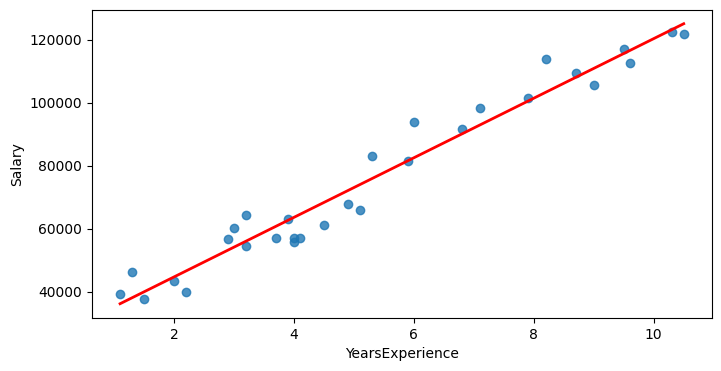

In [47]:
plt.figure(figsize=(8, 4))
sns.regplot(x='YearsExperience', y='Salary', data=salary_data, ci=None, line_kws={"color": "red", "lw": 2} )

In [52]:
y_pred = regressor.predict(x_test)
y_pred

array([75074.50510972, 91873.8056381 , 62008.38247653, 81607.56642631,
       67608.14931932, 89073.92221671])

In [54]:
comparison = pd.DataFrame({"Реальные значения:": y_test, "Предсказания:": y_pred})
comparison

,Реальные значения:,Предсказания:
0,83088.0,75074.505110
1,98273.0,91873.805638
2,63218.0,62008.382477
3,93940.0,81607.566426
4,61111.0,67608.149319
5,91738.0,89073.922217


### Оценка качества модели

In [59]:
mae = sklmetr.mean_absolute_error(y_test,y_pred)
mse = sklmetr.mean_squared_error(y_test,y_pred)
r2 = sklmetr.r2_score(y_test, y_pred)
print('MAE:', mae)
print('MSE:', mse)
print("R^2:", r2)

MAE: 6185.994575326634
MSE: 51338023.49224842
R^2: 0.7616681465472094


In [68]:
pd.set_option('display.float_format', '{:,.2f}'.format)
pd.DataFrame(data={"MAE": mae, "MSE": mse, "R^2": r2}, dtype=np.float64, index=[1])

,MAE,MSE,R^2
1,"6,185.99","51,338,023.49",0.76
